# Backlash of the X or Y axis

Analysis of a run of `test_backlash.py`. Every photo of the run is one CSV row:
round, side (`below` = after the slow +STEP, `above` = after +APPROACH and back), commanded position, encoder count, photo.
The axis is in the file name (`backlash_x_...` / `backlash_y_...`).

Each round is a pair of photos at the same commanded position; only the two photos of a round are compared.

1. **image**: per photo, the centre of the black dot; per round, its shift from `below` to `above`
2. **result**: backlash = that shift, from the image and from the encoder
3. **plot**: backlash per round

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# test_backlash.py writes to <repo>/encoder_test_data (not the encoder_test_data next to this notebook)
REPO = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / ".git").exists())
DATA_DIR = REPO / "encoder_test_data"
PLOT_DIR = DATA_DIR / "encoder_test_plots"   # the plots are saved here
PLOT_DIR.mkdir(exist_ok=True)

# the run: CSV of test_backlash.py, its photos are in <RUN>_photos
RUN = "backlash_x_20261016_090951"
CSV = DATA_DIR / f"{RUN}.csv"
PHOTO_DIR = DATA_DIR / f"{RUN}_photos"
IMAGE_CSV = DATA_DIR / f"{RUN}_image.csv"   # written by the image cell

UM_PER_PX = 0.1192      # pixel size on the calibration slide (10 um ruler period = 83.9 px)
# how the stage moves in the picture: "x" = left/right (X axis), "y" = up/down (Y axis);
# SIGN = +1 if + steps move the picture to +x / +y, -1 if the other way
PICTURE_DIR = "x"
SIGN = 1
UM_PER_STEP = 0.3125    # stage travel per motor step
UM_PER_COUNT = 1.95     # linear encoder, counts up for + steps

COLOR = "#eb6834"       # linear encoder, as the 24 h linear run

## 1. Image: backlash of every round

Per photo, the centre of the black dot: the mean position of all pixels darker than DARK, leaving out
BORDER pixels at the image edges (the edge of the field of view is dark too).
Per round, the shift of that centre from the `below` to the `above` photo.
`image_um` is the shift along PICTURE_DIR in stage direction; `dot_px` is the dot area, about the same in every photo.
One row per round, written to `<RUN>_image.csv`.

In [2]:
photos = pd.read_csv(CSV, comment="#", usecols=["round", "side", "encoder", "photo"])

DARK = 50      # grey value: darker pixels belong to the black dot
BORDER = 500   # [px] left out at the image edges, which are dark too

centres = []
for photo in photos.photo:
    img = np.asarray(Image.open(PHOTO_DIR / photo).convert("L"))
    y, x = np.nonzero(img[BORDER:-BORDER, BORDER:-BORDER] < DARK)
    centres.append((BORDER + x.mean(), BORDER + y.mean(), len(x)))
photos[["x_px", "y_px", "dot_px"]] = centres

below = photos[photos.side == "below"].set_index("round")
above = photos[photos.side == "above"].set_index("round")
pairs = pd.DataFrame({
    "dx_um": (above.x_px - below.x_px) * UM_PER_PX,
    "dy_um": (above.y_px - below.y_px) * UM_PER_PX,
    "dot_px": below.dot_px,
    "encoder_below": below.encoder,
    "encoder_above": above.encoder,
}).reset_index()
pairs["image_um"] = SIGN * pairs[f"d{PICTURE_DIR}_um"]
pairs["encoder_um"] = (pairs.encoder_above - pairs.encoder_below) * UM_PER_COUNT   # empty for Y
pairs.to_csv(IMAGE_CSV, index=False)
pairs.round(3)

,round,dx_um,dy_um,dot_px,encoder_below,encoder_above,image_um,encoder_um
0,1,10.363,-0.110,284178.0,38,43,10.363,9.75
1,2,10.908,-0.021,284231.0,37,43,10.908,11.70
2,3,9.890,-0.019,284044.0,37,43,9.890,11.70
3,4,10.032,-0.044,284108.0,38,43,10.032,9.75
4,5,9.775,-0.041,284102.0,39,43,9.775,7.80
5,6,9.436,-0.036,283958.0,38,43,9.436,9.75
6,7,9.161,-0.074,283931.0,38,43,9.161,9.75
7,8,9.636,-0.019,283979.0,39,43,9.636,7.80
8,9,8.363,-0.030,283916.0,39,42,8.363,5.85
9,10,9.066,-0.060,284056.0,38,43,9.066,9.75


## 2. Result

backlash = position after `above` - position after `below`, per round
(positive = the stage stops short of the target). Mean and standard deviation over the rounds.

In [3]:
pairs = pd.read_csv(IMAGE_CSV, usecols=["round", "image_um", "encoder_um"])

image, encoder = pairs.image_um, pairs.encoder_um
print(f"backlash image   = {image.mean():+.2f} +- {image.std():.2f} um = {image.mean() / UM_PER_STEP:+.1f} steps")
print(f"backlash encoder = {encoder.mean():+.2f} +- {encoder.std():.2f} um = {encoder.mean() / UM_PER_STEP:+.1f} steps")
pairs.round(2)

backlash image   = +9.66 +- 0.71 um = +30.9 steps
backlash encoder = +9.36 +- 1.79 um = +30.0 steps


,round,image_um,encoder_um
0,1,10.36,9.75
1,2,10.91,11.70
2,3,9.89,11.70
3,4,10.03,9.75
4,5,9.77,7.80
5,6,9.44,9.75
6,7,9.16,9.75
7,8,9.64,7.80
8,9,8.36,5.85
9,10,9.07,9.75


## 3. Plot

Backlash of every round: filled from the image, open from the encoder (steps of 1.95 um).

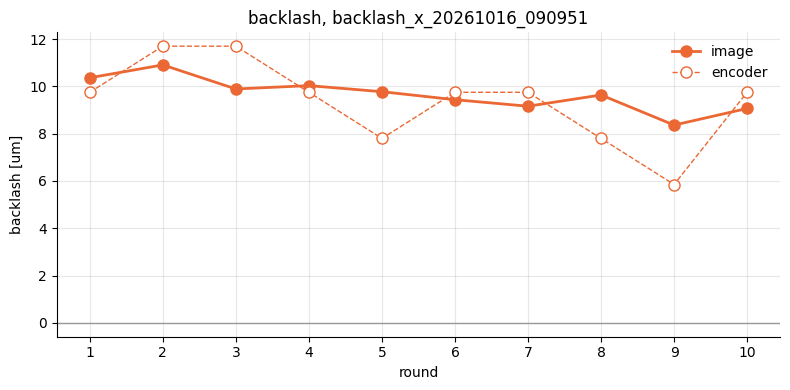

In [4]:
pairs = pd.read_csv(IMAGE_CSV, usecols=["round", "image_um", "encoder_um"])

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pairs["round"], pairs.image_um, "o-", color=COLOR, lw=2, ms=8, label="image")
ax.plot(pairs["round"], pairs.encoder_um, "o--", color=COLOR, lw=1, ms=8, mfc="white", label="encoder")
ax.axhline(0, color="0.6", lw=1)
ax.set_xlabel("round")
ax.set_ylabel("backlash [um]")
ax.set_xticks(pairs["round"])
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
ax.set_title(f"backlash, {RUN}")
fig.tight_layout()
fig.savefig(PLOT_DIR / f"{RUN}.png", dpi=150)
plt.show()